setosa - iterations: 32 - support vectors: 7
versicolor - iterations: 33 - support vectors: 29
virginica - iterations: 29 - support vectors: 27
Training accuracy: 96.0 %


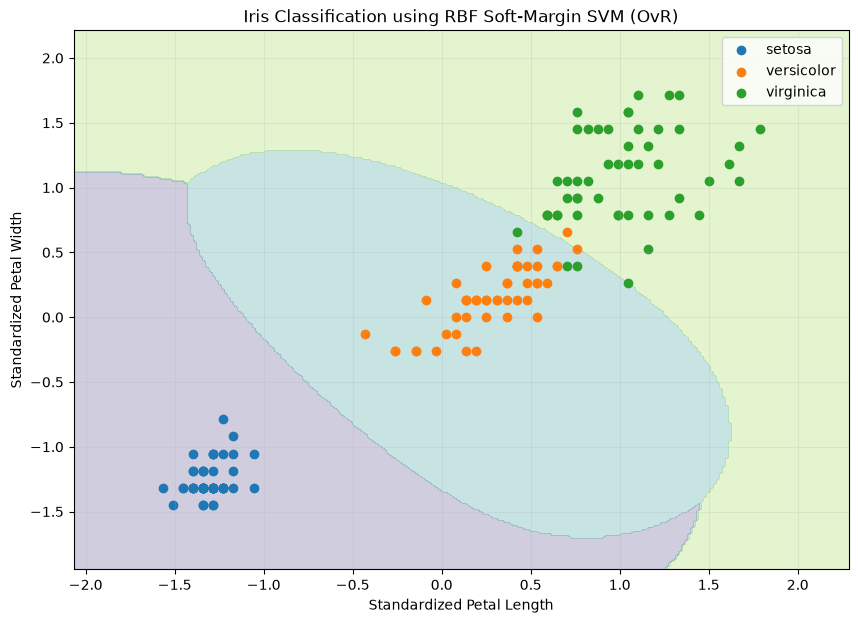

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# 1. Load the Iris dataset
iris = load_iris()

# Use only petal length and petal width for 2D visualization
X = iris.data[:, 2:4]
y = iris.target

class_names = iris.target_names

# Standardize the features
mean = np.mean(X, axis=0)
std = np.std(X, axis=0)
X = (X - mean) / std

# 2. RBF kernel
def rbf_kernel(X1, X2, gamma=0.5):
    K = np.zeros((len(X1), len(X2)))

    for i in range(len(X1)):
        for j in range(len(X2)):
            diff = X1[i] - X2[j]
            K[i, j] = np.exp(
                -gamma * np.sum(diff * diff)
            )

    return K


# 3. Your Soft-Margin SMO adapted for the RBF kernel
def soft_margin_smo_rbf(
    X, y, C=1.0, gamma=0.5, tol=1e-4,
    eps=1e-7, max_passes=20, max_iter=100000
):
    n = len(X)
    K = rbf_kernel(X, X, gamma)

    alpha = np.zeros(n)
    b = 0.0
    iterations = 0
    passes = 0

    def errors():
        return (alpha * y) @ K + b - y

    while passes < max_passes and iterations < max_iter:
        changed = 0
        E = errors()

        for i in range(n):
            Ei = E[i]
            ri = y[i] * Ei

            if not (
                (ri < -tol and alpha[i] < C - eps)
                or
                (ri > tol and alpha[i] > eps)
            ):
                continue

            candidates = sorted(
                (j for j in range(n) if j != i),
                key=lambda j: abs(Ei - E[j]),
                reverse=True
            )

            for j in candidates:
                Ej = E[j]
                ai_old, aj_old = alpha[i], alpha[j]

                if y[i] != y[j]:
                    L = max(0.0, aj_old - ai_old)
                    H = min(C, C + aj_old - ai_old)
                else:
                    L = max(0.0, ai_old + aj_old - C)
                    H = min(C, ai_old + aj_old)

                if H - L < eps:
                    continue

                eta = K[i, i] + K[j, j] - 2 * K[i, j]

                if eta <= eps:
                    continue

                aj_new = aj_old + y[j] * (Ei - Ej) / eta
                aj_new = np.clip(aj_new, L, H)

                if abs(aj_new - aj_old) < eps:
                    continue

                ai_new = ai_old + y[i] * y[j] * (
                    aj_old - aj_new
                )

                b1 = (
                    b - Ei
                    - y[i] * (ai_new - ai_old) * K[i, i]
                    - y[j] * (aj_new - aj_old) * K[i, j]
                )

                b2 = (
                    b - Ej
                    - y[i] * (ai_new - ai_old) * K[i, j]
                    - y[j] * (aj_new - aj_old) * K[j, j]
                )

                if eps < ai_new < C - eps:
                    b = b1
                elif eps < aj_new < C - eps:
                    b = b2
                else:
                    b = (b1 + b2) / 2

                alpha[i] = np.clip(ai_new, 0, C)
                alpha[j] = np.clip(aj_new, 0, C)

                changed += 1
                E = errors()
                break

        iterations += 1

        if changed == 0:
            passes += 1
        else:
            passes = 0

    return alpha, b, iterations


# 4. Train three binary classifiers using OvR
C = 1.0
gamma = 0.5

models = []

for class_id in range(3):
    # Current class = +1; other two classes = -1
    y_binary = np.where(y == class_id, 1.0, -1.0)

    alpha, b, iterations = soft_margin_smo_rbf(
        X, y_binary, C=C, gamma=gamma
    )

    models.append((alpha, b, y_binary))

    print(
        class_names[class_id],
        "- iterations:", iterations,
        "- support vectors:", np.sum(alpha > 1e-5)
    )


# 5. Predict using each classifier's decision score
def predict_ovr(X_train, X_new, models, gamma):
    scores = []

    for alpha, b, y_binary in models:
        K_new = rbf_kernel(X_new, X_train, gamma)
        score = K_new @ (alpha * y_binary) + b
        scores.append(score)

    # Select the class with the highest score
    return np.argmax(np.array(scores), axis=0)


y_pred = predict_ovr(X, X, models, gamma)

print(
    "Training accuracy:",
    round(np.mean(y_pred == y) * 100, 2),
    "%"
)


# 6. Build a grid for plotting
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.column_stack((xx.ravel(), yy.ravel()))

Z = predict_ovr(X, grid, models, gamma)
Z = Z.reshape(xx.shape)


# 7. Visualize the three classes and decision regions
plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, Z,
    levels=[-0.5, 0.5, 1.5, 2.5],
    alpha=0.25
)

for class_id in range(3):
    plt.scatter(
        X[y == class_id, 0],
        X[y == class_id, 1],
        label=class_names[class_id]
    )

plt.xlabel("Standardized Petal Length")
plt.ylabel("Standardized Petal Width")
plt.title("Iris Classification using RBF Soft-Margin SVM (OvR)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
